# POD compression and reconstruction of continuous EEG on a laptop

This demo uses **all 13 continuous Alljoined-1 recordings**, preserving all 64 channels and all samples at 512 Hz. Twelve recordings fit a common POD basis; subject 08 is the initial evaluation recording. We also exclude each of the eight participants in turn, including **all** of that participant's sessions. [Setup](README_neuro.md), [dataset paper](https://arxiv.org/abs/2404.05553).

The airfoil POD demo removes a mean flow and asks whether a few modes retain coherent fluctuations. Here we ask whether a compressed representation retains **EEG waveform fluctuations, power spectra, band power, and channel correlations**. The weather SVD demo reconstructs spatial snapshots; we reconstruct the full conditioned EEG and measure its errors.

This is batch compression: coefficients are computed from the recording being encoded, and its channel means are stored as metadata. Only the spatial basis is learned from other participants. Scores describe reconstruction, rather than predicting future samples or stimulus labels.

For the complete 1,520-recording Alljoined-1.6M corpus, actual disk encodings,
and an input larger than the RAM visible in the measured WSL2 environment, see the
[large EEG companion](pod_demo_eeg_large.ipynb). It uses a separate 32-electrode acquisition.

## 1. Inputs, units, and resource limits

FIF channel units, calibration, sample rates, and ordering are checked before fitting. The FIF files occupy about 5.9 GB; the 12-recording float32 training matrix is about 5.06 GiB. We read at most 131,072 output samples per task, with two CPU worker threads and one BLAS thread recommended in the setup instructions. Session boundaries pool snapshots for POD but are never treated as adjacent times for filtering or spectra.

In [1]:
from __future__ import annotations

import importlib.metadata
import json
import os
import sys
from pathlib import Path

import dask
import dask.array as da
import matplotlib.pyplot as plt
import mne
import numpy as np
import xarray as xr

sys.path.insert(0, str(Path.cwd().parent))
from demos.eeg_analysis import (
    band_power_errors,
    compression_ratio,
    correlation_matrix,
    covariance_modes,
    covariance_scores,
    filtered_eeg_file,
    participant_validation,
    reconstruction_spectra,
    recording_statistics,
)
from demos.eeg_utils import alljoined_paths, lazy_eeg_file, recording_manifest
from svdrom import POD

EEG_DIR = Path(os.environ.get("SVDROM_EEG_DIR", "data/alljoined1")).expanduser()
paths = alljoined_paths(EEG_DIR)
missing = [str(path) for path in paths if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing EEG files; see README_neuro.md: " + ", ".join(missing)
    )
manifest = recording_manifest(paths)
channel_names = tuple(manifest[0]["channels"])
sfreq = manifest[0]["sfreq"]
metadata = {path: item["n_samples"] for path, item in zip(paths, manifest, strict=True)}
subjects = [int(path.name[4:6]) for path in paths]
test_path = paths[-1]
train_paths = paths[:-1]
n_train = sum(metadata[path] for path in train_paths)
n_test = metadata[test_path]
chunk_samples = 131_072
high_pass = 0.5
halo_seconds = 32
ranks = (1, 2, 4, 8, 16, 32)
dask.config.set(scheduler="threads", num_workers=2)
plt.rcParams["figure.dpi"] = 85
rank_colors = {8: "tab:blue", 16: "tab:green", 32: "tab:orange"}
mne.set_log_level("WARNING")
versions = {
    name: importlib.metadata.version(name)
    for name in ("svdrom", "mne", "numpy", "dask", "xarray", "scipy")
}
print("Environment:", versions)
print(f"{len(paths)} recordings, {len(channel_names)} channels, {sfreq:g} Hz")
print(f"Training: {n_train:,} samples; held out: {n_test:,} samples")
print("All EEG units are volts; reader converts to µV once.")
print(
    "Calibration factors:",
    sorted({x for item in manifest for x in item["calibration"]}),
)
print(
    "Custom-reference flags:", sorted({item["custom_ref_applied"] for item in manifest})
)

Environment: {'svdrom': '0.1.0', 'mne': '1.13.2', 'numpy': '2.4.6', 'dask': '2026.7.1', 'xarray': '2026.7.0', 'scipy': '1.18.0'}
13 recordings, 64 channels, 512 Hz
Training: 21,225,984 samples; held out: 1,779,200 samples
All EEG units are volts; reader converts to µV once.
Calibration factors: [1.0]
Custom-reference flags: [0]


## 2. Audit the original recordings

One global training mean leaves large differences between session means in the pooled covariance. The previous raw-data fit captured 94.8% of training energy with eight modes, but about 97% of that pooled energy came from differences between session means. We reproduce that diagnosis from full-recording statistics below.

Each mean is computed in one blockwise pass, then the centered covariance in another. Only a 64-element mean and 64 × 64 covariance are kept per recording. Header calibration establishes consistency with the files; it does not independently establish hardware calibration or the physical acquisition reference.

Audited subj01_session1_eeg.fif


Audited subj01_session2_eeg.fif


Audited subj02_session1_eeg.fif


Audited subj03_session1_eeg.fif


Audited subj03_session2_eeg.fif


...

Audited subj05_session2_eeg.fif


Audited subj06_session1_eeg.fif


Audited subj06_session2_eeg.fif


Audited subj07_session1_eeg.fif


Audited subj08_session1_eeg.fif
Pooled training energy from session means: 97.0%
Original eight-mode pooled training energy: 94.8%
Original basis: held-out within-recording energy: 55.5%


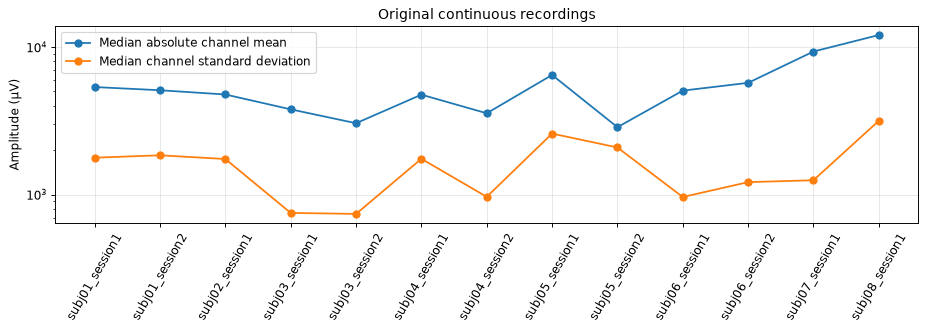

In [2]:
raw_statistics = []
for path in paths:
    values = lazy_eeg_file(path, metadata[path], channel_names, chunk_samples)
    raw_statistics.append(recording_statistics(values))
    print("Audited", path.name)
weights = np.asarray([s["n_samples"] for s in raw_statistics[:-1]])
raw_means = np.stack([s["mean"] for s in raw_statistics])
raw_stds = np.stack([np.sqrt(np.diag(s["covariance"])) for s in raw_statistics])
pooled_mean = np.average(raw_means[:-1], weights=weights, axis=0)
within_covariance = (
    sum(s["n_samples"] * s["covariance"] for s in raw_statistics[:-1]) / n_train
)
between_covariance = (
    sum(
        weight * np.outer(mean - pooled_mean, mean - pooled_mean)
        for weight, mean in zip(weights, raw_means[:-1], strict=True)
    )
    / n_train
)
raw_covariance = within_covariance + between_covariance
offset_fraction = np.trace(between_covariance) / np.trace(raw_covariance)
raw_modes = covariance_modes(raw_covariance, max(ranks))
raw_training = covariance_scores(raw_covariance, raw_modes, ranks)
raw_test = covariance_scores(raw_statistics[-1]["covariance"], raw_modes, ranks)
print(f"Pooled training energy from session means: {offset_fraction:.1%}")
print(f"Original eight-mode pooled training energy: {raw_training[8]['energy']:.1%}")
print(f"Original basis: held-out within-recording energy: {raw_test[8]['energy']:.1%}")
fig, ax = plt.subplots(figsize=(11, 4))
labels = [path.stem.removesuffix("_eeg") for path in paths]
ax.semilogy(
    labels,
    np.median(np.abs(raw_means), axis=1),
    "o-",
    label="Median absolute channel mean",
)
ax.semilogy(
    labels, np.median(raw_stds, axis=1), "o-", label="Median channel standard deviation"
)
ax.set(ylabel="Amplitude (µV)", title="Original continuous recordings")
ax.tick_params(axis="x", rotation=60)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 3. Define the fluctuation signal before compression

We apply a **0.5 Hz, fourth-order Butterworth high-pass in forward and reverse directions**, then subtract each recording's remaining channel means. The nominal cutoff corresponds to the authors' [0.5–125 Hz preprocessing option](https://github.com/Alljoined/alljoined-dataset1/blob/main/1_preprocessing/fif-eeg-preprocessing.py); our lightweight conditioning does not reproduce their full cleaning pipeline. Forward/reverse filtering squares the amplitude response, producing zero phase and effective eighth-order magnitude rolloff. [SciPy implementation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfiltfilt.html).

Every filtered block reads 32 seconds of real context on each side and discards those halos afterward. Only the recording ends use filter padding. Tests compare blocked filtering with whole-array filtering to check seams. No samples or channels are removed. The input remains in its original acquisition reference; eye activity, line noise, and other artifacts can still contribute variance.

The **reconstruction target is this conditioned signal**. Slow fluctuations intentionally removed by the filter cannot be recovered from its POD coefficients. We quantify the conditioning loss below. Means from the encoded recording are allowed in this batch-compression workflow and counted as stored metadata; they are not used to choose the spatial basis. This treatment would require different rules for forecasting or online decoding.

Conditioned subj01_session1_eeg.fif


Conditioned subj01_session2_eeg.fif


Conditioned subj02_session1_eeg.fif


Conditioned subj03_session1_eeg.fif


Conditioned subj03_session2_eeg.fif


...

Conditioned subj05_session2_eeg.fif


Conditioned subj06_session1_eeg.fif


Conditioned subj06_session2_eeg.fif


Conditioned subj07_session1_eeg.fif


Conditioned subj08_session1_eeg.fif
Fraction of original within-recording variance retained after conditioning:
  subj01_session1_eeg: 0.0028%
  subj01_session2_eeg: 0.0043%
  subj02_session1_eeg: 0.0069%
  subj03_session1_eeg: 12.1876%
  subj03_session2_eeg: 0.0097%
  subj04_session1_eeg: 0.0073%
  subj04_session2_eeg: 0.0024%
  subj05_session1_eeg: 0.0091%
  subj05_session2_eeg: 0.0112%
  subj06_session1_eeg: 0.0030%
  subj06_session2_eeg: 0.0050%
  subj07_session1_eeg: 0.0027%
  subj08_session1_eeg: 0.0016%
Training matrix: (64, 21225984), 5.06 GiB


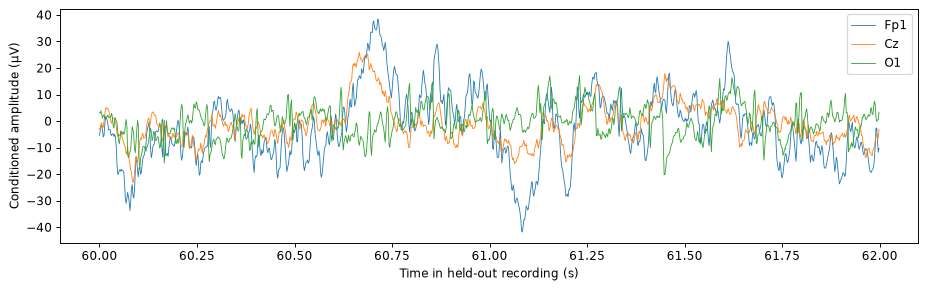

Largest conditioned channel-variance share in each recording:
subj01_session1_eeg.fif: AF8, 6.42%, standard deviation 22.3 µV
subj01_session2_eeg.fif: FT7, 6.58%, standard deviation 33.6 µV
subj02_session1_eeg.fif: F4, 20.82%, standard deviation 68.6 µV
subj03_session1_eeg.fif: PO4, 99.87%, standard deviation 3963.0 µV
subj03_session2_eeg.fif: Fpz, 4.63%, standard deviation 17.5 µV
subj04_session1_eeg.fif: AF8, 34.93%, standard deviation 83.8 µV
subj04_session2_eeg.fif: Fp2, 8.81%, standard deviation 18.1 µV
subj05_session1_eeg.fif: Fpz, 6.36%, standard deviation 55.7 µV
subj05_session2_eeg.fif: Fp1, 11.85%, standard deviation 64.5 µV
subj06_session1_eeg.fif: Fp2, 5.55%, standard deviation 16.7 µV
subj06_session2_eeg.fif: Fp2, 5.32%, standard deviation 16.9 µV
subj07_session1_eeg.fif: P9, 8.21%, standard deviation 27.6 µV
subj08_session1_eeg.fif: AF8, 5.04%, standard deviation 23.0 µV


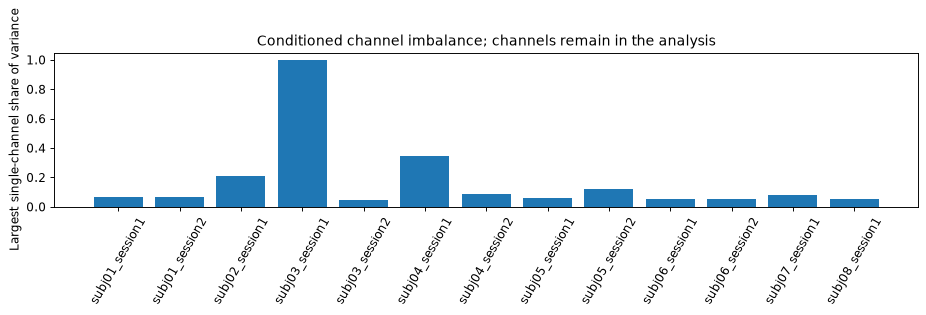

In [3]:
conditioned_files = []
conditioned_statistics = []
for path in paths:
    filtered = filtered_eeg_file(
        path,
        metadata[path],
        channel_names,
        chunk_samples,
        sfreq,
        high_pass,
        halo_seconds,
    )
    statistics = recording_statistics(filtered)
    conditioned_statistics.append(statistics)
    centered = (filtered.astype(np.float64) - statistics["mean"][:, None]).astype(
        np.float32
    )
    conditioned_files.append(centered)
    print("Conditioned", path.name)
retained_variance = np.asarray(
    [
        np.trace(after["covariance"]) / np.trace(before["covariance"])
        for before, after in zip(raw_statistics, conditioned_statistics, strict=True)
    ]
)
print("Fraction of original within-recording variance retained after conditioning:")
for path, fraction in zip(paths, retained_variance, strict=True):
    print(f"  {path.stem}: {fraction:.4%}")
train_data = da.concatenate(conditioned_files[:-1], axis=1)
test_data = conditioned_files[-1]
train_xr = xr.DataArray(
    train_data, dims=("channel", "sample"), coords={"channel": list(channel_names)}
)
test_xr = xr.DataArray(
    test_data,
    dims=("channel", "sample"),
    coords={"channel": list(channel_names), "sample": np.arange(n_test)},
)
print(f"Training matrix: {train_xr.shape}, {train_xr.nbytes / 1024**3:.2f} GiB")
preview_start = round(60 * sfreq)
preview_stop = preview_start + round(2 * sfreq)
preview = test_xr.isel(sample=slice(preview_start, preview_stop)).compute()
seconds = np.asarray(preview["sample"]) / sfreq
selected_channels = [channel_names.index(name) for name in ("Fp1", "Cz", "O1")]
fig, ax = plt.subplots(figsize=(11, 3.5))
for channel in selected_channels:
    ax.plot(seconds, preview[channel], label=channel_names[channel], linewidth=0.7)
ax.set(xlabel="Time in held-out recording (s)", ylabel="Conditioned amplitude (µV)")
ax.legend()
fig.tight_layout()
plt.show()
channel_dominance = []
for path, statistics in zip(paths, conditioned_statistics, strict=True):
    variance = np.maximum(np.diag(statistics["covariance"]), 0)
    channel = int(np.argmax(variance))
    channel_dominance.append(
        {
            "file": path.name,
            "channel": channel_names[channel],
            "standard_deviation_uv": float(np.sqrt(variance[channel])),
            "variance_fraction": float(variance[channel] / variance.sum()),
        }
    )
print("Largest conditioned channel-variance share in each recording:")
for item in channel_dominance:
    print(
        f"{item['file']}: {item['channel']}, {item['variance_fraction']:.2%}, "
        f"standard deviation {item['standard_deviation_uv']:.1f} µV"
    )
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(labels, [item["variance_fraction"] for item in channel_dominance])
ax.set(
    ylabel="Largest single-channel share of variance",
    ylim=(0, 1.05),
    title="Conditioned channel imbalance; channels remain in the analysis",
)
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()

## 4. Fit POD using every training snapshot

Per-recording centering is already applied, so `remove_mean=False` avoids another pooled mean. `compute_time_coeffs=False` keeps the 32 × N training coefficients lazy. Covariance POD accumulates all samples into a **64 × 64 spatial covariance**, then diagonalizes it. The modes span channels; coefficients and reconstructions retain the original sample count and order.

Covariance is appropriate for 64 channels and millions of snapshots. Its squared condition number makes weak modes less accurate than direct SVD, and storage grows quadratically with channel count. These are limitations of this particular backend.

The earlier audit matters here: participant 03/session 1 has an extreme PO4 imbalance. A dominant first training mode can therefore coexist with poor held-out reconstruction. The following energy curve is a training statistic, not evidence of transfer to another participant.

Mode shape: (64, 32)
Training coefficients remain lazy: True


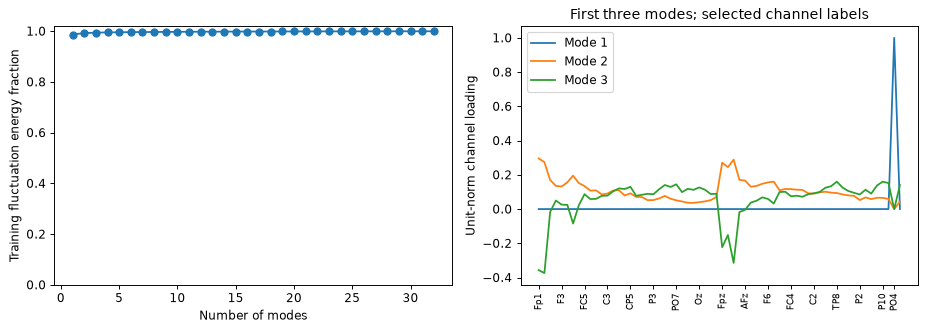

First mode: 98.7% training energy, 0.6% held-out energy.


In [4]:
pod = POD(
    n_modes=max(ranks),
    svd_algorithm="covariance",
    remove_mean=False,
    compute_time_coeffs=False,
    compute_energy_ratio=True,
    time_dimension="sample",
)
pod.fit(train_xr)
modes = np.asarray(pod.modes)
training_covariance = (
    sum(s["n_samples"] * s["covariance"] for s in conditioned_statistics[:-1]) / n_train
)
cached_modes = covariance_modes(training_covariance, max(ranks))
np.testing.assert_allclose(modes @ modes.T, cached_modes @ cached_modes.T, atol=1e-6)
training_scores = covariance_scores(training_covariance, modes, ranks)
test_covariance = conditioned_statistics[-1]["covariance"]
test_scores = covariance_scores(test_covariance, modes, ranks)
print("Mode shape:", pod.modes.shape)
print("Training coefficients remain lazy:", isinstance(pod.time_coeffs.data, da.Array))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(1, max(ranks) + 1), np.cumsum(pod.explained_energy_ratio), "o-")
axes[0].set(
    xlabel="Number of modes",
    ylabel="Training fluctuation energy fraction",
    ylim=(0, 1.02),
)
for mode in range(3):
    axes[1].plot(
        np.arange(len(channel_names)), modes[:, mode], label=f"Mode {mode + 1}"
    )
channel_ticks = sorted(
    set(range(0, len(channel_names), 4)) | {channel_names.index("PO4")}
)
axes[1].set(
    ylabel="Unit-norm channel loading",
    xticks=channel_ticks,
    xticklabels=[channel_names[i] for i in channel_ticks],
    title="First three modes; selected channel labels",
)
axes[1].tick_params(axis="x", rotation=90, labelsize=8)
axes[1].legend()
fig.tight_layout()
plt.show()
print(
    f"First mode: {training_scores[1]['energy']:.1%} training energy, "
    f"{test_scores[1]['energy']:.1%} held-out energy."
)

The following sensor maps use the named channels on a standard template. The source FIF files have no measured electrode positions. Colors show signed channel weights, whose sign is arbitrary; these maps are schematic, rather than neural source localization. Each panel has its own symmetric colour scale to show weaker modes; compare the numeric colour bars before comparing amplitudes.

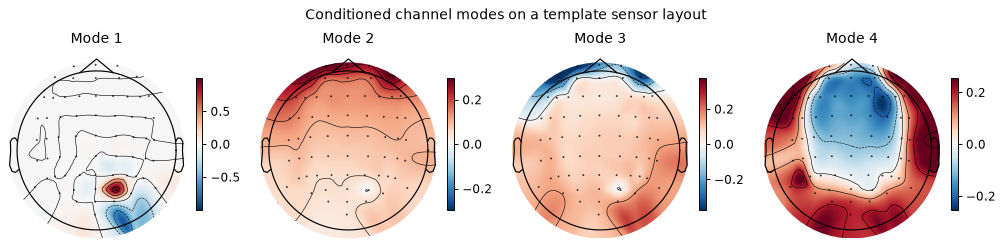

In [5]:
template_info = mne.create_info(list(channel_names), sfreq, ch_types="eeg")
template_info.set_montage(mne.channels.make_standard_montage("colin27_1020"))
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for mode, ax in enumerate(axes):
    image, _ = mne.viz.plot_topomap(
        modes[:, mode], template_info, axes=ax, show=False, cmap="RdBu_r"
    )
    ax.set_title(f"Mode {mode + 1}")
    fig.colorbar(image, ax=ax, shrink=0.65)
fig.suptitle("Conditioned channel modes on a template sensor layout")
fig.tight_layout()
plt.show()

## 5. Decode the compressed representation and score the entire held-out recording

With the scaling used by POD, $\widehat X_k=\sqrt{N_{train}}\,\Phi_{1:k}A_{1:k,test}$.
Adding the encoded recording's stored mean recovers the filtered recording; the errors are identical because both sides receive that same mean. The reference predicts zero fluctuation at every sample. We report $1-\|X-\widehat X_k\|_F^2/\|X\|_F^2$, RMSE, and the nominal storage ratio.

Full-recording covariance is a sufficient statistic for linear projection MSE and channel correlations. We use it to score every rank, and verify ranks 8 and 32 by actually reconstructing and reducing squared errors over **every held-out sample** through SVD-ROM. The nominal ratio counts float32 modes, coefficients, and channel means; it excludes container/coordinate overhead and makes no claim that preprocessing is lossless.

The decoded waveforms use float32 modes and coefficients, matching the stated storage ratio. Their measured errors are checked against the float64 covariance projection. Spectra use linear projections with the same float32 modes; they do not include the separately quantized coefficient path used for waveform decoding. Covariance and participant-fold summaries use float64 arithmetic. The large companion instead measures spectra from its actual saved float32 coefficients.


Encoded mode/coefficient/mean dtypes: float32 float32 float32


rank | train energy | held-out energy | RMSE µV | nominal ratio | corr RMSE
   1 | 0.9866 | 0.0062 | 12.755 | 64.00x | 0.6187
   2 | 0.9925 | 0.5812 | 8.280 | 32.00x | 0.5437
   4 | 0.9952 | 0.7388 | 6.539 | 16.00x | 0.3444
   8 | 0.9968 | 0.8125 | 5.540 | 8.00x | 0.2783
  16 | 0.9984 | 0.8811 | 4.411 | 4.00x | 0.1943
  32 | 0.9995 | 0.9483 | 2.910 | 2.00x | 0.1308


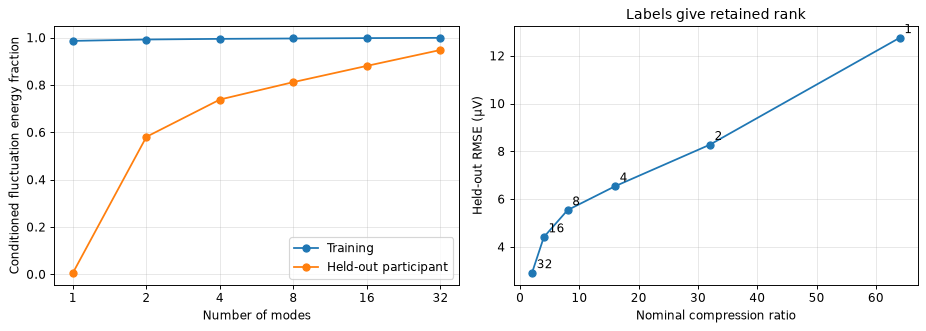

In [6]:
test_coefficients = pod.transform(test_xr, compute=False)
stored_modes = pod.modes.astype(np.float32)
stored_coefficients = test_coefficients.astype(np.float32)
stored_mean = conditioned_statistics[-1]["mean"].astype(np.float32)
print(
    "Encoded mode/coefficient/mean dtypes:",
    stored_modes.dtype,
    stored_coefficients.dtype,
    stored_mean.dtype,
)
reconstructions = {
    rank: (
        stored_modes.isel(components=slice(rank))
        @ stored_coefficients.isel(components=slice(rank))
    )
    * np.float32(np.sqrt(n_train))
    for rank in ranks
}
direct_errors = dask.compute(
    *[
        ((test_xr - reconstructions[rank]).astype(np.float64) ** 2).mean()
        for rank in (8, 32)
    ]
)
for rank, error in zip((8, 32), direct_errors, strict=True):
    np.testing.assert_allclose(float(error), test_scores[rank]["rmse"] ** 2, rtol=1e-5)
ratios = [compression_ratio(len(channel_names), n_test, rank) for rank in ranks]
print("rank | train energy | held-out energy | RMSE µV | nominal ratio | corr RMSE")
for rank, ratio in zip(ranks, ratios, strict=True):
    print(
        f"{rank:4d} | {training_scores[rank]['energy']:.4f} | "
        f"{test_scores[rank]['energy']:.4f} | {test_scores[rank]['rmse']:.3f} | "
        f"{ratio:.2f}x | {test_scores[rank]['correlation_rmse']:.4f}"
    )
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(
    ranks, [training_scores[k]["energy"] for k in ranks], "o-", label="Training"
)
axes[0].plot(
    ranks, [test_scores[k]["energy"] for k in ranks], "o-", label="Held-out participant"
)
axes[0].set(
    xlabel="Number of modes",
    ylabel="Conditioned fluctuation energy fraction",
    xticks=ranks,
)
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(ranks, labels=[str(k) for k in ranks])
axes[0].legend()
axes[1].plot(ratios, [test_scores[k]["rmse"] for k in ranks], "o-")
for rank, x in zip(ranks, ratios, strict=True):
    axes[1].annotate(
        str(rank),
        (x, test_scores[rank]["rmse"]),
        xytext=(4, 4),
        textcoords="offset points",
    )
axes[1].set(
    xlabel="Nominal compression ratio",
    ylabel="Held-out RMSE (µV)",
    title="Labels give retained rank",
)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

The waveform comparison uses an interior two-second window, away from the filter's recording-end padding. Unlike the previous raw-data plot, all curves share the same centering and amplitude scale. The channel-error panel uses the entire recording, preventing one attractive trace from standing in for the full result.

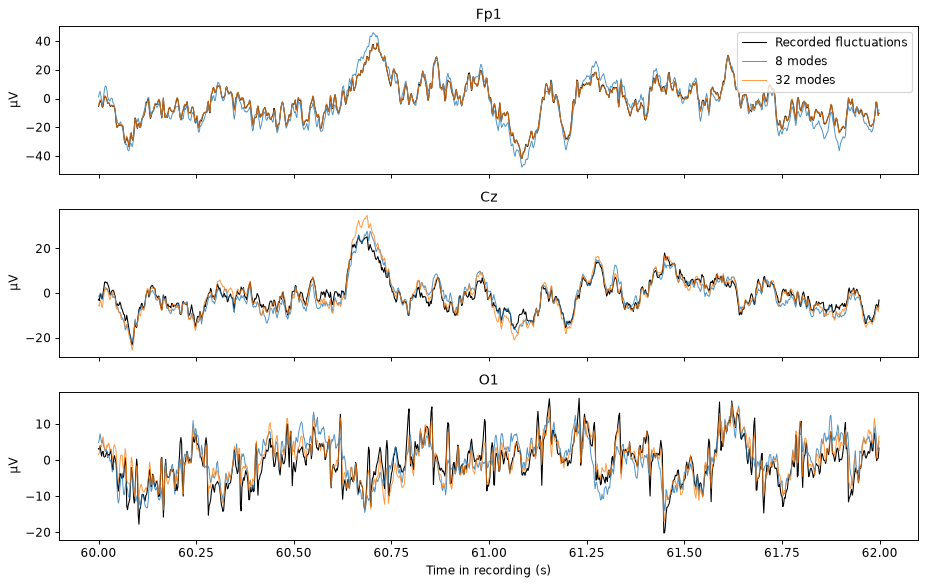

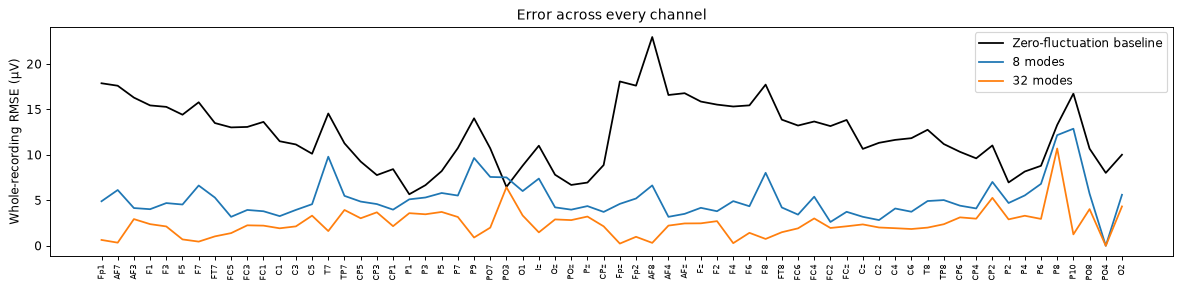

In [7]:
prediction_windows = dask.compute(
    *[
        reconstructions[k].isel(sample=slice(preview_start, preview_stop))
        for k in (8, 32)
    ]
)
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for channel, ax in zip(selected_channels, axes, strict=True):
    ax.plot(
        seconds,
        preview[channel],
        label="Recorded fluctuations",
        color="black",
        linewidth=0.9,
    )
    for rank, prediction in zip((8, 32), prediction_windows, strict=True):
        ax.plot(
            seconds,
            prediction[channel],
            label=f"{rank} modes",
            color=rank_colors[rank],
            linewidth=0.8,
            alpha=0.8,
        )
    ax.set(ylabel="µV", title=channel_names[channel])
axes[0].legend()
axes[-1].set_xlabel("Time in recording (s)")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(
    channel_names,
    np.sqrt(np.diag(test_covariance)),
    label="Zero-fluctuation baseline",
    color="black",
)
for rank in (8, 32):
    ax.plot(
        channel_names,
        test_scores[rank]["channel_rmse"],
        label=f"{rank} modes",
        color=rank_colors[rank],
    )
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.set(ylabel="Whole-recording RMSE (µV)", title="Error across every channel")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Does reconstruction retain temporal spectra and band power?

The airfoil demo compares coefficient spectra with a flow probe. Here we compare **recorded and reconstructed channel PSDs** and quantify band-power changes across all channels. Welch estimates use every complete eight-second window of the held-out recording with 50% overlap, aligned across processing tasks. The final incomplete window is excluded. [Welch definition](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html).

Alpha (8–13 Hz) and beta (13–30 Hz) are useful spectral descriptors, but preserving them does not establish neural origin. We also report delta, theta, 30–45 Hz, and 49–51/59–61 Hz line-noise bands. The authors apply a 60 Hz notch; we retain that band as a diagnostic so reconstruction cannot quietly hide a change in line-noise power. Relative errors are undefined for zero-power channels and excluded from medians.

Welch windows: 867; all complete windows in the held-out recording
Median absolute band-power error across channels (%):
1 {'delta 1-4': 100.0, 'theta 4-8': 100.0, 'alpha 8-13': 100.0, 'beta 13-30': 100.0, '30-45': 100.0, 'line 49-51': 100.0, 'line 59-61': 100.0}
2 {'delta 1-4': 50.44, 'theta 4-8': 56.24, 'alpha 8-13': 60.43, 'beta 13-30': 64.98, '30-45': 64.76, 'line 49-51': 65.29, 'line 59-61': 74.63}
4 {'delta 1-4': 23.51, 'theta 4-8': 29.79, 'alpha 8-13': 33.31, 'beta 13-30': 38.76, '30-45': 41.72, 'line 49-51': 46.5, 'line 59-61': 44.95}
8 {'delta 1-4': 19.75, 'theta 4-8': 23.04, 'alpha 8-13': 27.8, 'beta 13-30': 31.07, '30-45': 29.84, 'line 49-51': 32.32, 'line 59-61': 38.47}
16 {'delta 1-4': 11.13, 'theta 4-8': 10.85, 'alpha 8-13': 13.03, 'beta 13-30': 17.07, '30-45': 16.13, 'line 49-51': 21.25, 'line 59-61': 25.12}
32 {'delta 1-4': 5.21, 'theta 4-8': 4.65, 'alpha 8-13': 7.26, 'beta 13-30': 7.72, '30-45': 8.39, 'line 49-51': 11.98, 'line 59-61': 11.92}


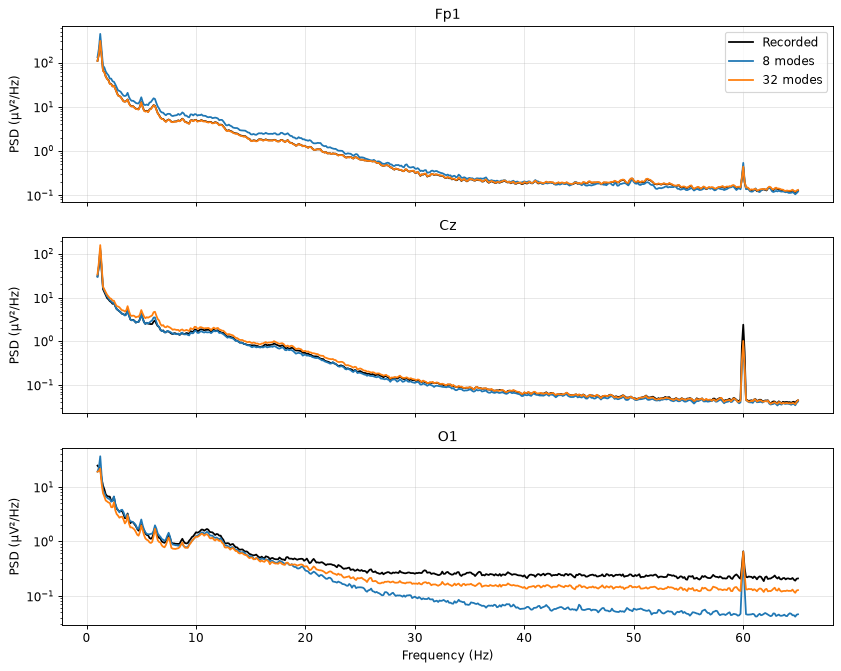

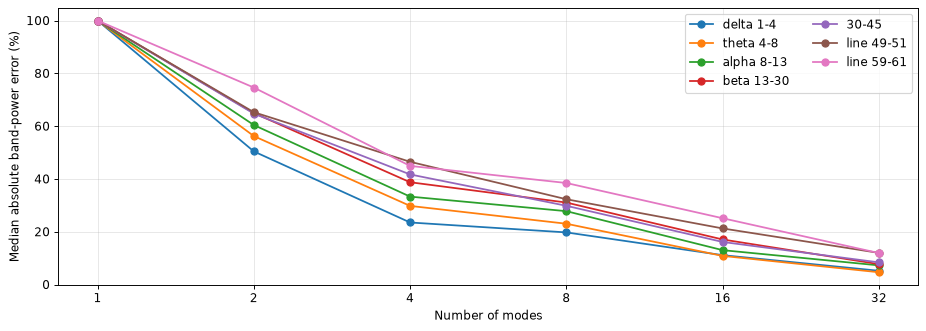

In [8]:
frequency, spectra, n_welch_windows = reconstruction_spectra(
    test_data, np.asarray(stored_modes), ranks, sfreq
)
bands = {
    "delta 1-4": (1, 4),
    "theta 4-8": (4, 8),
    "alpha 8-13": (8, 13),
    "beta 13-30": (13, 30),
    "30-45": (30, 45),
    "line 49-51": (49, 51),
    "line 59-61": (59, 61),
}
band_errors = band_power_errors(frequency, spectra, bands)
print(
    f"Welch windows: {n_welch_windows}; all complete windows in the held-out recording"
)
print("Median absolute band-power error across channels (%):")
for rank_index, rank in enumerate(ranks):
    print(
        rank,
        {
            name: round(float(np.nanmedian(np.abs(errors[rank_index]))) * 100, 2)
            for name, errors in band_errors.items()
        },
    )
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
band = (frequency >= 1) & (frequency <= 65)
for channel, ax in zip(selected_channels, axes, strict=True):
    ax.semilogy(
        frequency[band], spectra[0, channel, band], label="Recorded", color="black"
    )
    for rank in (8, 32):
        ax.semilogy(
            frequency[band],
            spectra[1 + ranks.index(rank), channel, band],
            label=f"{rank} modes",
            color=rank_colors[rank],
        )
    ax.set(ylabel="PSD (µV²/Hz)", title=channel_names[channel])
    ax.grid(alpha=0.3)
axes[0].legend()
axes[-1].set_xlabel("Frequency (Hz)")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(11, 4))
for name, errors in band_errors.items():
    ax.plot(ranks, np.nanmedian(np.abs(errors), axis=1) * 100, "o-", label=name)
ax.set(
    xlabel="Number of modes",
    ylabel="Median absolute band-power error (%)",
    xticks=ranks,
)
ax.set_xscale("log", base=2)
ax.set_xticks(ranks, labels=[str(k) for k in ranks])
ax.legend(ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 7. Does reconstruction retain channel relationships?

These correlation matrices are analytical projections of the covariance of every conditioned sample. They do not separately simulate coefficient quantization. Recorded and reconstructed correlations use the fixed [-1, 1] scale; the difference panel has its own symmetric scale, labelled in correlation units. Correlation RMSE averages the off-diagonal upper triangle, excluding undefined constant-channel entries. Near-perfect waveform energy does not guarantee preservation of every channel relationship, especially for low-amplitude channels. Correlation preservation is a statistical reconstruction check; it is not a claim about functional connectivity.

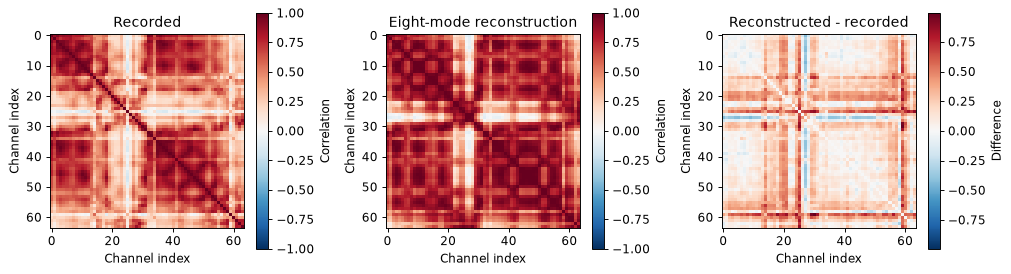

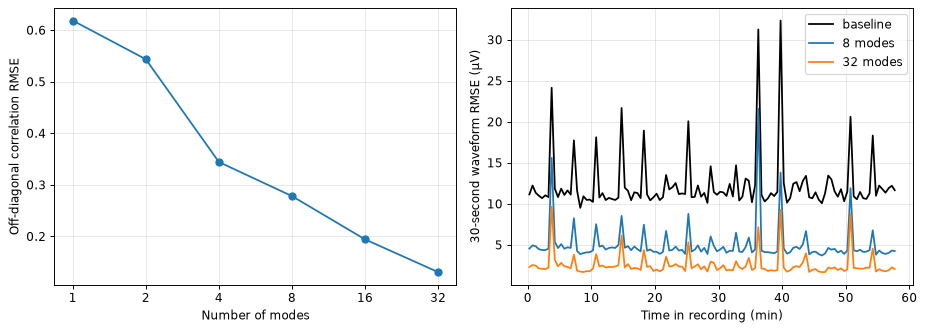

In [9]:
original_correlation = correlation_matrix(test_covariance)
reconstructed_correlation = correlation_matrix(
    test_scores[8]["reconstructed_covariance"]
)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, matrix, title in zip(
    axes,
    (
        original_correlation,
        reconstructed_correlation,
        reconstructed_correlation - original_correlation,
    ),
    ("Recorded", "Eight-mode reconstruction", "Reconstructed - recorded"),
    strict=True,
):
    is_difference = title == "Reconstructed - recorded"
    limit = max(float(np.nanmax(np.abs(matrix))), 1e-12) if is_difference else 1
    image = ax.imshow(matrix, vmin=-limit, vmax=limit, cmap="RdBu_r")
    ax.set(title=title, xlabel="Channel index", ylabel="Channel index")
    fig.colorbar(
        image,
        ax=ax,
        shrink=0.75,
        label="Difference" if is_difference else "Correlation",
    )
fig.tight_layout()
plt.show()
window_samples = round(30 * sfreq)
windowed = xr.Dataset(
    {
        "baseline": (test_xr.astype(np.float64) ** 2)
        .mean("channel")
        .coarsen(sample=window_samples, boundary="pad")
        .mean(),
        "8 modes": ((test_xr - reconstructions[8]).astype(np.float64) ** 2)
        .mean("channel")
        .coarsen(sample=window_samples, boundary="pad")
        .mean(),
        "32 modes": ((test_xr - reconstructions[32]).astype(np.float64) ** 2)
        .mean("channel")
        .coarsen(sample=window_samples, boundary="pad")
        .mean(),
    }
).compute()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ranks, [test_scores[k]["correlation_rmse"] for k in ranks], "o-")
axes[0].set(
    xlabel="Number of modes", ylabel="Off-diagonal correlation RMSE", xticks=ranks
)
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(ranks, labels=[str(k) for k in ranks])
for name, color in (
    ("baseline", "black"),
    ("8 modes", rank_colors[8]),
    ("32 modes", rank_colors[32]),
):
    axes[1].plot(
        windowed["sample"] / sfreq / 60,
        np.sqrt(windowed[name]),
        label=name,
        color=color,
    )
axes[1].set(xlabel="Time in recording (min)", ylabel="30-second waveform RMSE (µV)")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 8. Validate across all eight participants

For each fold, all sessions belonging to one participant are excluded from fitting. The same conditioning and rank grid are used in every fold. This is an exploratory reconstruction demo: participants are held out from basis fitting, but the workflow was developed after inspecting this dataset. These are not blind confirmatory results. Each recording is centered as part of encoding, using its own stored mean. Training recordings are weighted by their sample counts.

Cached **N × covariance** summaries reproduce, up to float32 centering and accumulation roundoff, the covariance of concatenated centered training recordings. The small NumPy eigenproblem uses the same mathematics as SVD-ROM's covariance backend, avoiding eight repeated full-dataset disk scans. Above, its initial-fold subspace is checked against the actual SVD-ROM fit, and reconstruction scores are checked against the full waveform calculation.

The participant-specific optimum fits modes to the evaluation participant and is shown only as a descriptive upper bound. It is not a held-out model. We report an equal-participant mean and the observed range, rather than treating millions of correlated samples as independent experimental replications.

Held-out participant energy fractions:
Subject 01: {1: 0.0085, 2: 0.3975, 4: 0.5823, 8: 0.6517, 16: 0.7615, 32: 0.9012}
Subject 02: {1: 0.0035, 2: 0.2023, 4: 0.3214, 8: 0.4155, 16: 0.595, 32: 0.7769}
Subject 03: {1: 0.0037, 2: 0.0234, 4: 0.0479, 8: 0.0582, 16: 0.0841, 32: 0.8701}
Subject 04: {1: 0.0181, 2: 0.4074, 4: 0.6703, 8: 0.7105, 16: 0.8424, 32: 0.9601}
Subject 05: {1: 0.0094, 2: 0.5046, 4: 0.6708, 8: 0.7484, 16: 0.8283, 32: 0.9245}
Subject 06: {1: 0.0082, 2: 0.5319, 4: 0.6838, 8: 0.7834, 16: 0.8823, 32: 0.9556}
Subject 07: {1: 0.0035, 2: 0.5107, 4: 0.6327, 8: 0.7121, 16: 0.8215, 32: 0.9239}
Subject 08: {1: 0.0062, 2: 0.5812, 4: 0.7388, 8: 0.8125, 16: 0.8811, 32: 0.9483}
8 modes: equal-participant mean 61.2%; range 5.8%-81.3%
32 modes: equal-participant mean 90.8%; range 77.7%-96.0%


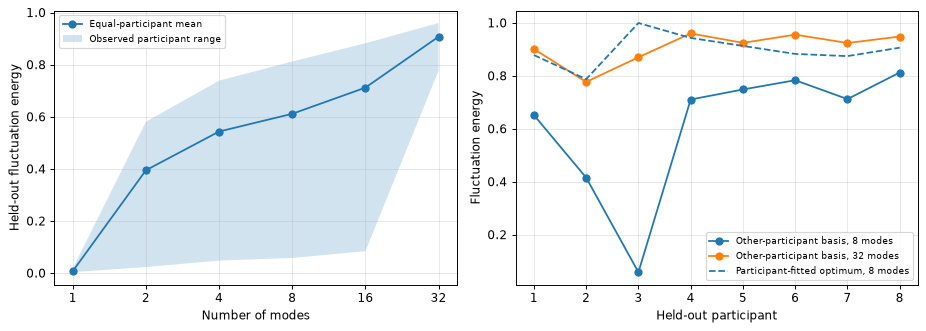

In [10]:
folds = participant_validation(conditioned_statistics, subjects, ranks)
subject08 = next(fold for fold in folds if fold["subject"] == 8)
np.testing.assert_allclose(
    subject08["ranks"][8]["test_energy"], test_scores[8]["energy"], rtol=1e-6
)
validation_energy = np.asarray(
    [[fold["ranks"][k]["test_energy"] for k in ranks] for fold in folds]
)
print("Held-out participant energy fractions:")
for fold in folds:
    print(
        f"Subject {fold['subject']:02d}:",
        {k: round(fold["ranks"][k]["test_energy"], 4) for k in ranks},
    )
for rank in (8, 32):
    values = validation_energy[:, ranks.index(rank)]
    print(
        f"{rank} modes: equal-participant mean {values.mean():.1%}; "
        f"range {values.min():.1%}-{values.max():.1%}"
    )
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(
    ranks, validation_energy.mean(axis=0), "o-", label="Equal-participant mean"
)
axes[0].fill_between(
    ranks,
    validation_energy.min(axis=0),
    validation_energy.max(axis=0),
    alpha=0.2,
    label="Observed participant range",
)
axes[0].set(
    xlabel="Number of modes", ylabel="Held-out fluctuation energy", xticks=ranks
)
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(ranks, labels=[str(k) for k in ranks])
for rank in (8, 32):
    axes[1].plot(
        [fold["subject"] for fold in folds],
        validation_energy[:, ranks.index(rank)],
        "o-",
        label=f"Other-participant basis, {rank} modes",
        color=rank_colors[rank],
    )
axes[1].plot(
    [fold["subject"] for fold in folds],
    [fold["ranks"][8]["test_optimal_energy"] for fold in folds],
    "--",
    label="Participant-fitted optimum, 8 modes",
)
axes[1].set(
    xlabel="Held-out participant", ylabel="Fluctuation energy", xticks=range(1, 9)
)
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
validation_report = {
    "versions": versions,
    "preprocessing": {
        "high_pass_hz": high_pass,
        "filter_order": 4,
        "zero_phase": True,
        "halo_seconds": halo_seconds,
        "per_recording_center": True,
    },
    "ranks": list(ranks),
    "manifest": manifest,
    "pooled_raw_offset_energy_fraction": float(offset_fraction),
    "conditioning_retained_variance": retained_variance.tolist(),
    "subject08": {
        k: {
            "energy": float(test_scores[k]["energy"]),
            "rmse": float(test_scores[k]["rmse"]),
            "correlation_rmse": float(test_scores[k]["correlation_rmse"]),
            "compression_ratio": compression_ratio(len(channel_names), n_test, k),
        }
        for k in ranks
    },
    "median_absolute_band_power_error": {
        name: np.nanmedian(np.abs(errors), axis=1).tolist()
        for name, errors in band_errors.items()
    },
    "welch_windows": n_welch_windows,
    "conditioned_channel_dominance": channel_dominance,
    "encoding_dtype": "float32",
    "participant_folds": folds,
}
_ = Path("eeg_validation.json").write_text(
    json.dumps(validation_report, indent=2) + "\n"
)

## 9. Resource scaling of the revised workflow

From the repository root run `uv run --locked --extra demos --extra neuro python -m demos.benchmark_eeg`. The benchmark includes high-pass conditioning, estimation of each recording's mean, fitting, projection, and scoring. Counts 1, 4, and 12 use fresh processes with two Dask workers and one BLAS thread. Peak RSS includes imports and all worker stages; timings reflect shared-host and filesystem-cache effects.

The saved report identifies the preprocessing configuration and package versions. It measures the compact fit/evaluation workflow, excluding notebook figures, Welch analysis, participant-fold analysis, filesystem cache, and other processes. The corpus is smaller than the RAM visible inside the measured WSL2 environment; memory far below input size is the claim established here.

Reference benchmark: Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.39 {'svdrom': '0.1.0', 'numpy': '2.4.6', 'dask': '2026.7.1', 'xarray': '2026.7.0', 'mne': '1.13.2', 'scipy': '1.18.0', 'psutil': '7.2.2'}
Shared host; filesystem cache is not cleared between runs.


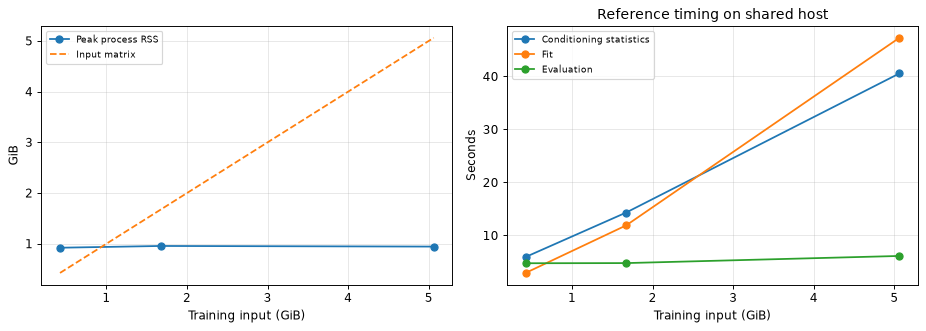

In [11]:
benchmark_path = Path("eeg_benchmark.json")
if benchmark_path.is_file():
    benchmark = json.loads(benchmark_path.read_text())
    expected = {
        "high_pass_hz": high_pass,
        "halo_seconds": halo_seconds,
        "filter_order": 4,
        "zero_phase": True,
        "per_recording_center": True,
    }
    if benchmark.get("preprocessing") != expected:
        msg = "Benchmark predates revised conditioning; rerun demos.benchmark_eeg."
        raise ValueError(msg)
    print("Reference benchmark:", benchmark["platform"], benchmark["versions"])
    print(benchmark["timing_context"])
    cases = benchmark["cases"]
    sizes = [case["training_gib"] for case in cases]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(
        sizes, [case["peak_rss_gib"] for case in cases], "o-", label="Peak process RSS"
    )
    axes[0].plot(sizes, sizes, "--", label="Input matrix")
    axes[0].set(xlabel="Training input (GiB)", ylabel="GiB")
    for field, label in [
        ("conditioning_seconds", "Conditioning statistics"),
        ("fit_seconds", "Fit"),
        ("evaluation_seconds", "Evaluation"),
    ]:
        axes[1].plot(sizes, [case[field] for case in cases], "o-", label=label)
    axes[1].set(
        xlabel="Training input (GiB)",
        ylabel="Seconds",
        title="Reference timing on shared host",
    )
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
else:
    print("Run demos.benchmark_eeg to generate resource measurements.")

## 10. Interpret compression and preservation together

The result table gives the actual tradeoff: fewer modes yield greater nominal compression, while reconstruction error, spectral distortion, and correlation error determine what survives. The eight-participant evaluation distinguishes an unusually favorable recording from a consistent result across participants. High fluctuation energy alone does not establish preservation of alpha/beta power or every channel relationship.

Conditioning removes the session-offset dominance and slow drift before defining the target. Its discarded variance is reported explicitly; these scores do not claim recovery of the unfiltered source. Remaining reference effects, electrode artifacts, ocular activity, and line noise can still influence the modes. Template sensor positions and unsupervised channel patterns cannot establish physiological sources.

The scientific structure now parallels the existing demos: define the fluctuation signal as in airfoil POD, encode and reconstruct as in ERA5 SVD, and check errors against a baseline as in weather DMD. The reference CPU benchmark demonstrates processing memory well below input size across this corpus in WSL2. It does not identify the physical laptop RAM or guarantee the same timings on every laptop. These measured properties support an EEG compression example without requiring a stimulus-decoding task.

In the checked run, subject 08 retained **81.3%** fluctuation energy with eight modes (nominal **8x** float32 storage reduction) and **94.8%** with 32 modes (**2x**). Median absolute alpha/beta power errors fell from about **28%/31%** at eight modes to **7%/8%** at 32. These are empirical tradeoffs, rather than a claim that all spectral properties survive aggressive compression.

Across eight held-out participants, eight-mode energy retention averaged **61.2%**, with an observed **5.8%-81.3%** range. At 32 modes it averaged **90.8%**, with a **77.7%-96.0%** range. Participant 03 is unusual: PO4 in its first session contributes **99.87%** of that conditioned recording's variance, with about **3963 µV** standard deviation. That large channel imbalance dominates the pooled first mode; the poor transfer to/from this participant is consistent with this imbalance. This association does not establish its acquisition cause. It is retained and flagged explicitly, rather than silently excluded. The declared FIF bad-channel list is not sufficient assurance of signal quality.

This dataset therefore supports a measured compression/reconstruction demonstration and a useful quality-control lesson. More raw training variance captured does not guarantee preservation of other participants' waveforms, frequency bands, or correlations. The outlier requires acquisition-aware investigation before physiological interpretation; conditioning and larger rank do not establish that the retained signal is neural.
